# 🧠 Redes Neuronales: Inspiración Fisiológica
### Ingeniería Biomédica · Introducción a Señales Biomédicas
**Ing. Alexander Valdez** — Cuaderno práctico (Google Colab)

---

> **Pregunta guía de la clase:** *¿Cómo podemos construir una computadora capaz de aprender a reconocer patrones, de manera similar a como lo hace nuestro cerebro?*

En este cuaderno vamos a **programar en Python** cada idea de la clase y resolver el **ejercicio introductorio**: construir un sistema que analice un electrocardiograma (ECG) y decida si presenta un patrón compatible con una **arritmia**.

| # | Sección | Diapositivas |
|---|---------|--------------|
| 0 | Cómo usar este cuaderno | — |
| 1 | Python mínimo para la clase | — |
| 2 | ¿Qué es una red neuronal? Reglas vs. aprendizaje | 1, 3 |
| 3 | ¿Cómo funciona una neurona por dentro? $z = \sum w_i x_i + b$, $y = f(z)$ | 4 |
| 4 | ¿Qué significa aprender? Pérdida y descenso de gradiente | 4, 5 |
| 5 | **Ejercicio introductorio: detección de arritmias en 10 000 ECG** | 7 |
| 5.1 | Recolección y etiquetado de los registros | |
| 5.2 | Pregunta 1: ¿podemos escribir todas las reglas a mano? | |
| 5.3 | Pregunta 2: ¿qué información necesita aprender la computadora? | |
| 5.4 | Pregunta 3: ¿cómo sabe si su predicción es correcta? | |
| 5.5 | Pregunta 4: ¿cómo mejora después de equivocarse? | |
| 5.6 | Integramos todo: el sistema completo | |
| 6 | Conclusiones | |
| 7 | Ejercicios propuestos y soluciones | |

📖 **Lectura recomendada:** *Patterns, predictions, and actions: A story about machine learning* — Moritz Hardt y Benjamin Recht → https://mlstory.org/

## 0. Cómo usar este cuaderno

- Un notebook tiene **celdas de texto** (como esta) y **celdas de código**.
- Para ejecutar una celda de código: haz clic en ella y presiona **`Shift + Enter`** (o el botón ▶️).
- Ejecuta las celdas **en orden, de arriba hacia abajo**: muchas usan variables creadas antes.
- Si algo falla: menú **Entorno de ejecución → Reiniciar y ejecutar todo**.
- Las líneas que empiezan con `#` son **comentarios**: Python las ignora, son explicaciones para ti.

Todas las librerías que usaremos ya vienen instaladas en Colab. Solo hay que **importarlas**:

In [ ]:
import numpy as np                  # cálculo numérico: vectores y matrices
import pandas as pd                 # tablas de datos
import matplotlib.pyplot as plt     # gráficos
from scipy.signal import butter, filtfilt, find_peaks   # procesamiento de señales

np.random.seed(42)                  # resultados reproducibles
plt.rcParams["figure.figsize"] = (10, 3.5)
print("¡Librerías cargadas correctamente!")

¡Librerías cargadas correctamente!


---
## 1. Python mínimo para esta clase

### 1.1 Variables
Una **variable** guarda un valor con un nombre. Python reconoce el tipo automáticamente.

In [ ]:
frecuencia_cardiaca = 72      # entero (int), en latidos por minuto
intervalo_qrs = 0.09          # decimal (float), en segundos
diagnostico = "Normal"        # texto (str)

print("FC:", frecuencia_cardiaca, "lpm")
print("QRS:", intervalo_qrs * 1000, "ms")
print("Diagnóstico:", diagnostico)

FC: 72 lpm
QRS: 90.0 ms
Diagnóstico: Normal


### 1.2 Listas, ciclos `for` y condiciones `if`
Una **lista** guarda varios valores; `for` los recorre uno por uno; `if` toma decisiones.

In [ ]:
registros_fc = [65, 72, 118, 54, 95]     # FC de 5 pacientes

for fc in registros_fc:
    if fc > 100:
        print(fc, "lpm -> FC elevada")
    elif fc < 60:
        print(fc, "lpm -> FC baja")
    else:
        print(fc, "lpm -> FC en rango normal")

65 lpm -> FC en rango normal
72 lpm -> FC en rango normal
118 lpm -> FC elevada
54 lpm -> FC baja
95 lpm -> FC en rango normal


### 1.3 Funciones
Una **función** recibe entradas, hace un cálculo y devuelve una salida con `return`.

> 💡 Una red neuronal es, en el fondo, **una función matemática con parámetros ajustables**.

In [ ]:
def fc_desde_rr(rr_segundos):
    # Convierte un intervalo RR (en segundos) a frecuencia cardiaca (lpm)
    return 60 / rr_segundos

print(fc_desde_rr(0.8), "lpm")   # RR de 0.8 s -> 75 lpm
print(fc_desde_rr(0.5), "lpm")   # RR de 0.5 s -> 120 lpm

75.0 lpm
120.0 lpm


### 1.4 NumPy: operar con vectores
Las señales biomédicas son **vectores de números** (una muestra por instante de tiempo). NumPy permite operar con todos los valores a la vez.

In [ ]:
rr = np.array([0.80, 0.82, 0.79, 0.81, 0.80])   # intervalos RR de un paciente (s)

print("FC de cada latido:", (60 / rr).round(1))
print("RR promedio:", rr.mean(), "s")
print("Desviación estándar RR:", rr.std().round(4), "s")
print("Número de intervalos:", len(rr))

FC de cada latido: [75.  73.2 75.9 74.1 75. ]
RR promedio: 0.804 s
Desviación estándar RR: 0.0102 s
Número de intervalos: 5


### 1.5 Gráficos con Matplotlib

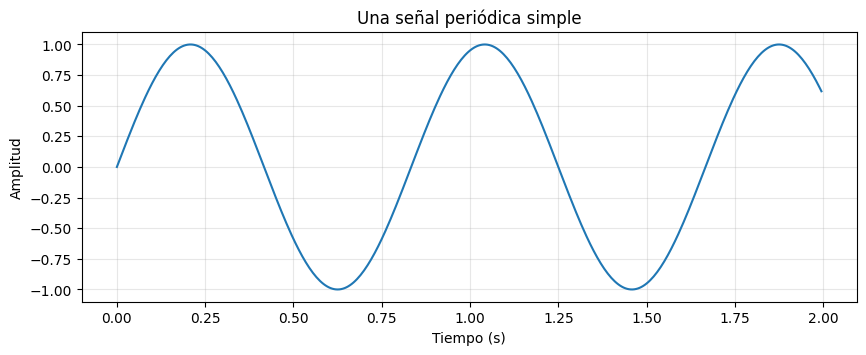

In [ ]:
fs = 200                               # frecuencia de muestreo: 200 muestras por segundo
t = np.arange(0, 2, 1 / fs)            # 2 segundos de tiempo
senal = np.sin(2 * np.pi * 1.2 * t)    # una onda de 1.2 Hz (equivale a 72 lpm)

plt.plot(t, senal)
plt.xlabel("Tiempo (s)"); plt.ylabel("Amplitud"); plt.title("Una señal periódica simple")
plt.grid(alpha=0.3); plt.show()

---
## 2. ¿Qué es una red neuronal?

Es un **modelo computacional inspirado en cómo se conectan las neuronas del cerebro** y cómo transmiten información. Su objetivo es **aprender patrones a partir de datos** para hacer predicciones o clasificaciones.

### ¿Qué problema resuelven? Dos enfoques

| Enfoque 1: Programación tradicional | Enfoque 2: Redes neuronales |
|---|---|
| El **programador define las reglas** manualmente | Damos **miles de señales ECG etiquetadas** |
| *“Si la FC supera X, si el intervalo es mayor que Y…”* | La red **aprende patrones** ajustando sus parámetros |
| Clasificación según las reglas escritas | Identifica patrones en **ECG nuevos** |

La red neuronal resulta especialmente útil cuando:
- no conocemos todas las reglas que describen un fenómeno,
- hay relaciones complejas entre las variables,
- los datos tienen **ruido y variabilidad**,
- es difícil diseñar a mano un algoritmo que identifique todos los patrones.

### Breve historia
| Año | Hito |
|---|---|
| **1943** | McCulloch y Pitts: modelo matemático de una neurona; representa operaciones lógicas |
| **1958** | Rosenblatt: el **Perceptrón**, que aprende de ejemplos ajustando sus parámetros |
| **1986** | Rumelhart, Hinton y Williams popularizan **Backpropagation** para entrenar redes multicapa |
| **2010 →** | **Aprendizaje profundo**: más datos, GPU, redes convolucionales y recurrentes |

### Mini ejemplo: la neurona de McCulloch y Pitts (1943)
En 1943 los pesos y el umbral **se elegían a mano**. Aun así, una neurona ya podía representar **operaciones lógicas**:

In [ ]:
def neurona_mcp(x1, x2, w1, w2, umbral):
    # La neurona "dispara" (1) si la suma ponderada alcanza el umbral
    return 1 if (w1 * x1 + w2 * x2) >= umbral else 0

print("x1 x2 | AND | OR")
for x1 in [0, 1]:
    for x2 in [0, 1]:
        y_and = neurona_mcp(x1, x2, 1, 1, umbral=2)
        y_or = neurona_mcp(x1, x2, 1, 1, umbral=1)
        print(f" {x1}  {x2} |  {y_and}  |  {y_or}")

x1 x2 | AND | OR
 0  0 |  0  |  0
 0  1 |  0  |  1
 1  0 |  0  |  1
 1  1 |  1  |  1


💡 La **misma neurona** se comporta distinto según sus **parámetros**. El gran salto posterior (Perceptrón, 1958) fue que **la máquina encontrara esos parámetros sola, a partir de ejemplos**. Eso es lo que haremos a continuación.

---
## 3. ¿Cómo funciona una red neuronal por dentro?

Cada neurona artificial **recibe valores numéricos, les asigna pesos, suma los resultados y aplica una función de activación**:

$$z = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n + b \qquad\qquad y = f(z)$$

| Elemento | Significado |
|---|---|
| $x$ | Datos de entrada |
| $w$ | Pesos que aprende la red |
| $b$ | Sesgo o término independiente |
| $z$ | Suma ponderada |
| $f$ | Función de activación |
| $y$ | Salida de la neurona |

### 3.1 Una neurona programada paso a paso
Supongamos que la neurona recibe 3 características de un ECG: **frecuencia cardiaca**, **variabilidad RR** y **ancho del QRS**.

In [ ]:
# Entradas (x): características de un ECG (ya normalizadas, sin unidades)
x = np.array([0.8, 1.5, -0.3])     # [FC, variabilidad RR, ancho QRS]

# Parámetros (por ahora elegidos a mano; luego la red los APRENDERÁ)
w = np.array([0.4, 1.2, 0.7])      # pesos
b = -0.5                           # sesgo

# Paso 1: suma ponderada (forma "manual")
z = w[0] * x[0] + w[1] * x[1] + w[2] * x[2] + b
print("z (manual) =", round(z, 3))

# La misma operación con NumPy: producto punto
z = np.dot(w, x) + b
print("z (NumPy)  =", round(z, 3))

z (manual) = 1.41
z (NumPy)  = 1.41


### 3.2 Funciones de activación $f(z)$
La función de activación transforma la suma $z$ en la salida de la neurona. Las más comunes:

- **Sigmoide:** $\sigma(z) = \dfrac{1}{1+e^{-z}}$ → da un valor entre 0 y 1, que interpretamos como **probabilidad** (por ejemplo, probabilidad de arritmia).
- **ReLU:** $\text{ReLU}(z) = \max(0, z)$ → muy usada en capas ocultas.
- **Escalón:** la del modelo de 1943 (0 o 1).

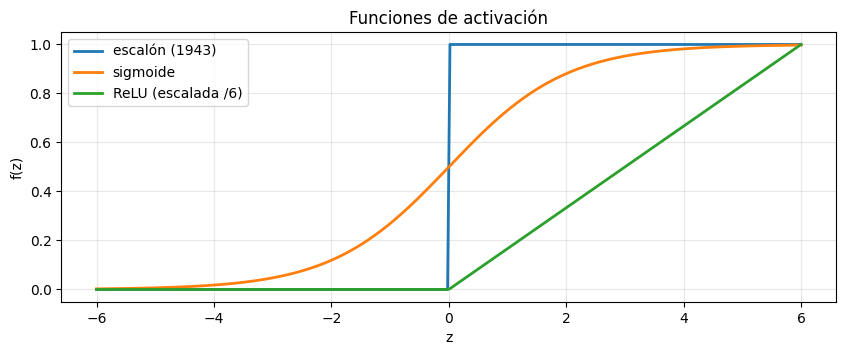

Salida de nuestra neurona: y = f(z) = 0.804  ->  80.4 % de probabilidad de arritmia


In [ ]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

zz = np.linspace(-6, 6, 300)
plt.plot(zz, np.where(zz >= 0, 1, 0), label="escalón (1943)", lw=2)
plt.plot(zz, sigmoide(zz), label="sigmoide", lw=2)
plt.plot(zz, relu(zz) / 6, label="ReLU (escalada /6)", lw=2)
plt.xlabel("z"); plt.ylabel("f(z)"); plt.title("Funciones de activación")
plt.legend(); plt.grid(alpha=0.3); plt.show()

y = sigmoide(z)
print(f"Salida de nuestra neurona: y = f(z) = {y:.3f}  ->  {y*100:.1f} % de probabilidad de arritmia")

### 3.3 De una neurona a una red
Una **red neuronal** conecta muchas neuronas organizadas en **capas**: una capa de entrada, una o más **capas ocultas** y una capa de salida. Con NumPy, una capa completa es una **multiplicación de matrices**:

$$\mathbf{z} = \mathbf{x}\,W + \mathbf{b}$$

In [ ]:
# Capa oculta con 4 neuronas que reciben las mismas 3 entradas
W1 = np.random.randn(3, 4) * 0.5     # 3 entradas x 4 neuronas
b1 = np.zeros(4)
h = relu(x @ W1 + b1)                # salidas de la capa oculta
print("Salidas de la capa oculta:", h.round(3))

# Neurona de salida que recibe las 4 salidas ocultas
W2 = np.random.randn(4, 1) * 0.5
b2 = np.zeros(1)
y_red = sigmoide(h @ W2 + b2)
print("Salida de la red:", y_red.round(3))

Salidas de la capa oculta: [0.093 0.    1.513 1.255]
Salida de la red: [0.162]


---
## 4. ¿Qué significa aprender?

**Aprender significa encontrar los valores de los pesos y sesgos que hacen que la red produzca resultados cada vez más cercanos a los esperados.**

El aprendizaje tiene **cuatro etapas** que se repiten muchas veces:

1. **Entrada:** entregamos los datos a la red.
2. **Predicción** (*forward propagation*): la red procesa los datos y genera una respuesta.
3. **Evaluación:** comparamos la predicción con el resultado esperado mediante una **función de pérdida**.
4. **Actualización** (*backpropagation* + *gradient descent*): calculamos gradientes y ajustamos los pesos para reducir el error.

La idea matemática central es **minimizar la función de pérdida**:

$$\min_{\mathbf{w},\,b} \; L(\mathbf{w}, b)$$

Y cada peso se actualiza con la regla del **descenso de gradiente**:

$$w_{\text{nuevo}} = w_{\text{anterior}} - \alpha\,\frac{\partial L}{\partial w}$$

donde $\alpha$ es la **tasa de aprendizaje** (*learning rate*) y $\dfrac{\partial L}{\partial w}$ es el **gradiente**: indica hacia dónde aumenta el error, así que nos movemos en la dirección contraria.

### 4.1 Intuición: bajar una montaña con los ojos vendados
Imagina una pérdida sencilla que depende de un solo peso: $L(w) = (w-3)^2$. El mínimo está en $w = 3$, pero la red **no lo sabe**: solo puede “sentir la pendiente” (el gradiente) y dar pasitos cuesta abajo.

Peso final: 2.9811  (el óptimo es 3)


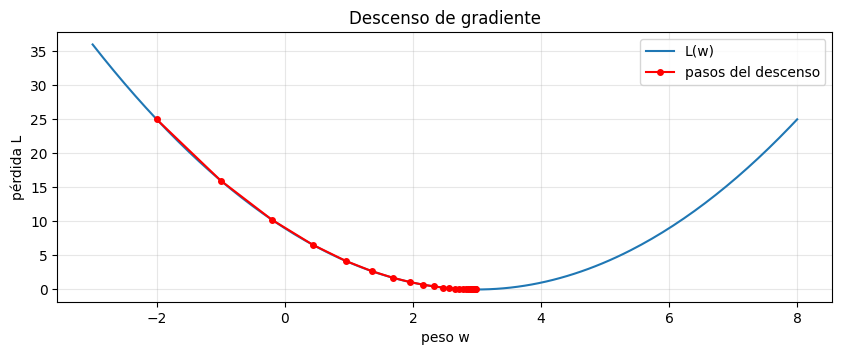

In [ ]:
def L(w):            # función de pérdida de ejemplo
    return (w - 3) ** 2

def dL_dw(w):        # su derivada (gradiente)
    return 2 * (w - 3)

w = -2.0             # peso inicial (una mala adivinanza)
alpha = 0.1          # tasa de aprendizaje
trayectoria = [w]

for paso in range(25):
    w = w - alpha * dL_dw(w)          # w_nuevo = w_anterior - alpha * dL/dw
    trayectoria.append(w)

print(f"Peso final: {w:.4f}  (el óptimo es 3)")

ws = np.linspace(-3, 8, 200)
plt.plot(ws, L(ws), label="L(w)")
plt.plot(trayectoria, [L(v) for v in trayectoria], "o-", color="red", ms=4, label="pasos del descenso")
plt.xlabel("peso w"); plt.ylabel("pérdida L"); plt.title("Descenso de gradiente")
plt.legend(); plt.grid(alpha=0.3); plt.show()

🔬 **Experimenta:** cambia `alpha` a `0.01` (muy pequeño), `0.5` y `1.05` (muy grande) y vuelve a ejecutar. ¿Qué pasa en cada caso?

---
# 5. 🫀 Ejercicio introductorio: detección de arritmias

> **Tenemos 10 000 registros de electrocardiogramas.** Algunos corresponden a pacientes sanos y otros presentan alteraciones cardíacas. Queremos desarrollar un sistema que analice un **nuevo** ECG y determine si presenta un patrón compatible con una **arritmia**. *¿Cómo podríamos enseñarle a una computadora a hacer esta tarea?*

Responderemos con código las **cuatro preguntas** de la clase:
1. ¿Podemos escribir a mano todas las reglas necesarias para identificar cualquier arritmia?
2. ¿Qué información necesitaría aprender una computadora?
3. ¿Cómo sabría si su predicción es correcta o incorrecta?
4. ¿Cómo podría mejorar después de cometer un error?

## 5.1 Recolección y etiquetado: generamos los 10 000 registros

En la práctica usaríamos bases de datos reales como la **MIT-BIH Arrhythmia Database** (PhysioNet). Para que el cuaderno funcione sin descargas, vamos a **simular** ECG realistas con:

- las ondas **P, QRS y T** de cada latido,
- **ruido**: deriva de línea base (respiración/movimiento), interferencia de la red eléctrica (60 Hz) y ruido muscular,
- variabilidad entre pacientes (amplitud, frecuencia).

Generaremos tres tipos de registro:

| Tipo | Etiqueta | Características fisiológicas |
|---|---|---|
| **Ritmo sinusal normal** | Normal (0) | Onda P presente, QRS estrecho. Incluye FC altas por ejercicio o estrés (hasta 125 lpm) y **arritmia sinusal respiratoria** (el RR varía suavemente al respirar: es fisiológico) |
| **Fibrilación auricular (FA)** | Arritmia (1) | RR **irregularmente irregular**, **sin onda P** (ondas “f” pequeñas) |
| **Extrasístoles ventriculares (ESV)** | Arritmia (1) | Latidos **prematuros** con **QRS ancho**, sin onda P, seguidos de pausa compensatoria |

> ℹ️ No necesitas entender cada línea de la función generadora: lo importante es que produce señales con las mismas dificultades que las reales.

In [ ]:
FS = 200     # frecuencia de muestreo (Hz)
DUR = 10     # duración de cada registro (s)

def ondas(t, centros, amp, ancho):
    # Suma de "campanas" gaussianas: cada una representa una onda (P, Q, R, S o T)
    return (amp[:, None] * np.exp(-((t[None, :] - centros[:, None]) ** 2) / (2 * ancho[:, None] ** 2))).sum(axis=0)

def generar_ecg(tipo, rng, fs=FS, dur=DUR):
    # Genera un ECG sintético de 'dur' segundos. tipo: 'normal', 'fa' o 'esv'
    t = np.arange(0, dur, 1 / fs)
    n = 40
    if tipo == "normal":
        fc = rng.uniform(55, 125)
        rr = np.full(n, 60 / fc) * (1 + rng.normal(0, 0.025, n))        # RR casi constante
        if rng.random() < 0.4:   # arritmia sinusal respiratoria: el RR varía suavemente con la respiración (¡es normal!)
            rr *= 1 + rng.uniform(0.05, 0.15) * np.sin(2 * np.pi * np.arange(n) / rng.uniform(3, 6))
        esv = np.zeros(n, bool); onda_p = np.ones(n, bool)
    elif tipo == "fa":
        fc = rng.uniform(60, 150)
        rr = np.full(n, 60 / fc) * (1 + rng.normal(0, rng.uniform(0.06, 0.25), n))   # RR irregular
        rr = np.clip(rr, 0.3, 2.0)
        esv = np.zeros(n, bool); onda_p = np.zeros(n, bool)              # sin onda P
    else:  # 'esv'
        fc = rng.uniform(55, 110)
        rr = np.full(n, 60 / fc) * (1 + rng.normal(0, 0.025, n))
        esv = np.zeros(n, bool)
        idx = rng.choice(np.arange(2, 14), size=rng.integers(1, 4), replace=False)
        esv[idx] = True
        rr[idx - 1] *= 0.6        # el latido llega antes (prematuro)
        rr[idx] *= 1.4            # pausa compensatoria
        onda_p = ~esv
    r_t = np.cumsum(rr) - rr[0] * rng.uniform(0.2, 1.0)                 # instantes de cada onda R
    ok = (r_t > -0.5) & (r_t < dur + 0.5)
    r_t, esv, onda_p = r_t[ok], esv[ok], onda_p[ok]
    k = rng.uniform(0.7, 1.3)                                           # amplitud propia del paciente
    uno = np.ones(len(r_t))
    s  = ondas(t, r_t,        np.where(esv, 1.4, 1.0) * k, np.where(esv, rng.uniform(0.018, 0.035), 0.010) * rng.uniform(0.9, 1.1))  # R
    s += ondas(t, r_t - 0.03, -0.12 * k * uno, 0.008 * uno)                                                     # Q
    s += ondas(t, r_t + 0.03, -0.20 * k * uno, 0.008 * uno)                                                     # S
    s += ondas(t, r_t - 0.18,  0.12 * k * onda_p, 0.022 * uno)                                                  # P
    s += ondas(t, r_t + 0.30, np.where(esv, -0.35, 0.28) * k, 0.045 * uno)                                      # T
    if tipo == "fa":
        s += 0.03 * np.sin(2 * np.pi * rng.uniform(5, 8) * t + rng.uniform(0, 6))                              # ondas f
    # --- Ruido ---
    s += rng.uniform(0.1, 0.4) * np.sin(2 * np.pi * rng.uniform(0.1, 0.4) * t + rng.uniform(0, 6))  # deriva de línea base
    s += rng.uniform(0, 0.05) * np.sin(2 * np.pi * 60 * t)                                          # red eléctrica 60 Hz
    s += rng.normal(0, rng.uniform(0.01, 0.08), t.size)                                             # ruido muscular
    return s.astype(np.float32)

t_ecg = np.arange(0, DUR, 1 / FS)
print("Cada registro tiene", len(t_ecg), "muestras (", DUR, "s a", FS, "Hz )")

Cada registro tiene 2000 muestras ( 10 s a 200 Hz )


Veamos un ejemplo de cada tipo antes de generar los 10 000:

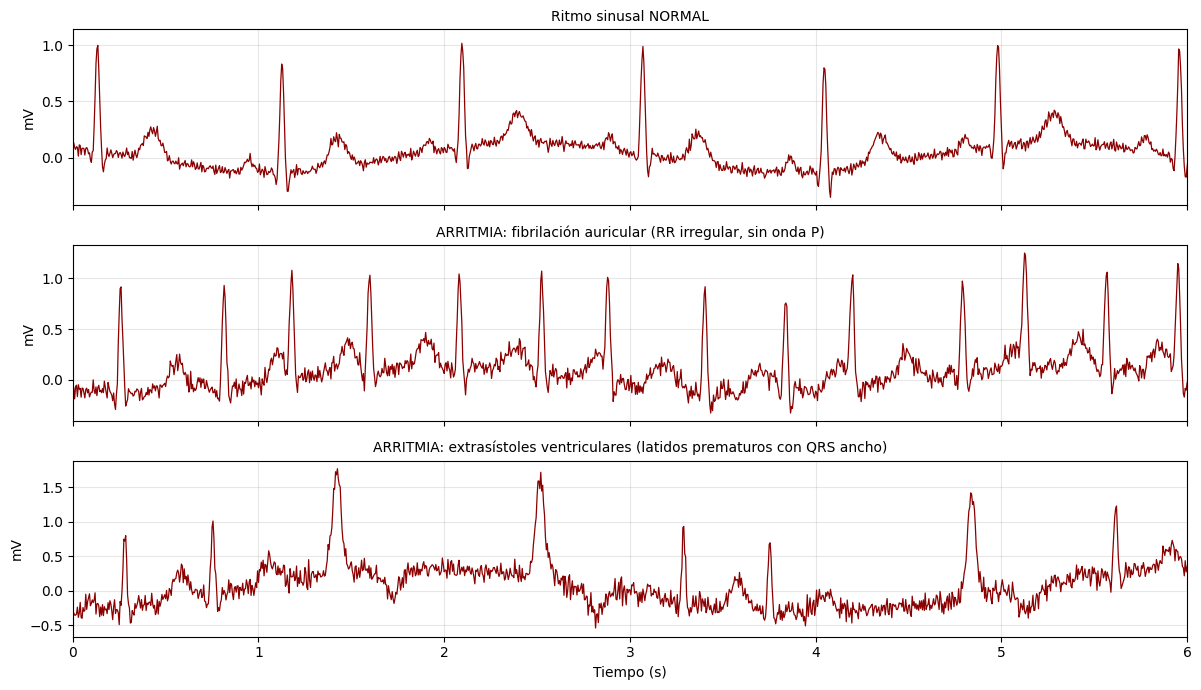

In [ ]:
rng_demo = np.random.default_rng(3)
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
titulos = {"normal": "Ritmo sinusal NORMAL", "fa": "ARRITMIA: fibrilación auricular (RR irregular, sin onda P)",
           "esv": "ARRITMIA: extrasístoles ventriculares (latidos prematuros con QRS ancho)"}
for ax, tipo in zip(axes, ["normal", "fa", "esv"]):
    ax.plot(t_ecg, generar_ecg(tipo, rng_demo), lw=0.9, color="darkred")
    ax.set_title(titulos[tipo], fontsize=10); ax.set_ylabel("mV"); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Tiempo (s)"); axes[-1].set_xlim(0, 6)
plt.tight_layout(); plt.show()

✅ **Qué observar:** a simple vista notamos la **deriva de la línea base** (la señal “ondula”) y el ruido. También vemos que la FA tiene latidos a intervalos desiguales y que las ESV tienen latidos más anchos y que llegan antes de tiempo.

### Generamos y etiquetamos los 10 000 registros
Esto toma unos 15–20 segundos.

In [ ]:
N = 10_000
rng = np.random.default_rng(2026)
tipos = rng.choice(["normal", "fa", "esv"], size=N, p=[0.5, 0.25, 0.25])

ecgs = np.stack([generar_ecg(tp, rng) for tp in tipos])        # matriz: 10 000 registros x 2000 muestras
etiquetas = (tipos != "normal").astype(int)                     # 0 = Normal, 1 = Arritmia

registros = pd.DataFrame({
    "Registro": [f"ECG_{i+1:05d}" for i in range(N)],
    "Señal ECG": ["Registro de señal"] * N,
    "Etiqueta": np.where(etiquetas == 1, "Arritmia", "Normal"),
    "Tipo (detalle)": tipos,
})
print("Forma de la matriz de señales:", ecgs.shape)
print(registros["Etiqueta"].value_counts(), "\n")
registros.head(8)

Forma de la matriz de señales: (10000, 2000)
Etiqueta
Arritmia    5065
Normal      4935
Name: count, dtype: int64 



,Registro,Señal ECG,Etiqueta,Tipo (detalle)
0,ECG_00001,Registro de señal,Normal,normal
1,ECG_00002,Registro de señal,Arritmia,fa
2,ECG_00003,Registro de señal,Normal,normal
3,ECG_00004,Registro de señal,Normal,normal
4,ECG_00005,Registro de señal,Normal,normal
5,ECG_00006,Registro de señal,Arritmia,esv
6,ECG_00007,Registro de señal,Arritmia,esv
7,ECG_00008,Registro de señal,Normal,normal


---
## 5.2 Pregunta 1: ¿podemos escribir a mano todas las reglas?

Probemos el **Enfoque 1 (programación tradicional)**. Una regla típica sería:

> *“Si la frecuencia cardiaca supera 100 lpm, es una arritmia.”*

Para aplicarla necesitamos medir la FC de cada registro. Lo haremos en la sección 5.3 con más detalle; por ahora usamos una función de apoyo.

In [ ]:
def preprocesar(senal, fs=FS):
    # 1) Elimina la deriva de línea base (filtro pasa-altos 0.5 Hz)
    b, a = butter(2, 0.5, btype="highpass", fs=fs)
    senal = filtfilt(b, a, senal)
    # 2) Elimina ruido de alta frecuencia y de la red eléctrica (filtro pasa-bajos 40 Hz)
    b, a = butter(4, 40, btype="lowpass", fs=fs)
    senal = filtfilt(b, a, senal)
    # 3) Normalización Z-score: media 0 y desviación estándar 1
    return (senal - senal.mean()) / senal.std()

def detectar_picos_r(senal_limpia, fs=FS):
    # Detecta las ondas R: picos altos separados al menos 0.25 s
    umbral = 0.5 * np.percentile(senal_limpia, 99.5)
    picos, _ = find_peaks(senal_limpia, height=umbral, distance=int(0.25 * fs))
    return picos

def frecuencia_cardiaca(senal, fs=FS):
    picos = detectar_picos_r(preprocesar(senal, fs), fs)
    rr = np.diff(picos) / fs                 # intervalos RR en segundos
    return 60 / rr.mean()

fc_todos = np.array([frecuencia_cardiaca(s) for s in ecgs[:2000]])   # usamos 2000 registros
y_2000 = etiquetas[:2000]

# --- REGLA MANUAL ---
pred_regla = (fc_todos > 100).astype(int)
exactitud_regla = np.mean(pred_regla == y_2000)
print(f"Exactitud de la regla 'FC > 100 lpm':  {exactitud_regla*100:.1f} %")

Exactitud de la regla 'FC > 100 lpm':  51.0 %


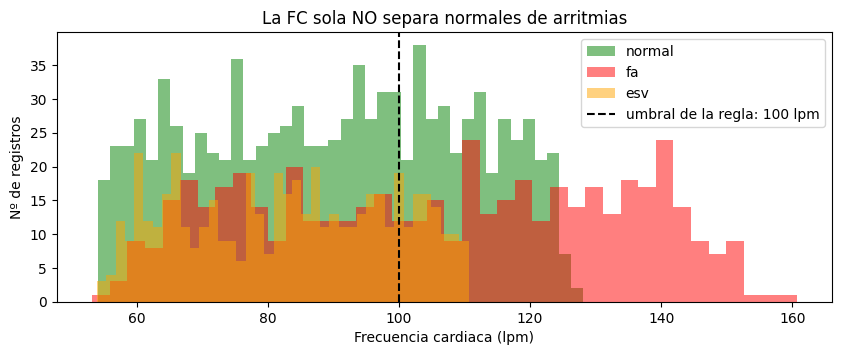

In [ ]:
plt.figure(figsize=(10, 3.5))
for tp, color in [("normal", "green"), ("fa", "red"), ("esv", "orange")]:
    plt.hist(fc_todos[tipos[:2000] == tp], bins=40, alpha=0.5, color=color, label=tp)
plt.axvline(100, color="k", ls="--", label="umbral de la regla: 100 lpm")
plt.xlabel("Frecuencia cardiaca (lpm)"); plt.ylabel("Nº de registros")
plt.title("La FC sola NO separa normales de arritmias"); plt.legend(); plt.show()

✅ **Qué observar:** la regla acierta apenas en torno al **50 %**, casi como lanzar una moneda. Las distribuciones de FC se **superponen**:
- Muchos pacientes **normales** tienen FC > 100 (ejercicio, estrés, actividad fisiológica normal).
- Muchas **arritmias** (sobre todo ESV) tienen FC normal.

Podríamos agregar más reglas (intervalos RR, ancho del QRS…), pero aparecen más dificultades: hay distintos tipos de arritmias, las señales tienen ruido, cada paciente es diferente, dos alteraciones pueden parecerse y una misma arritmia puede manifestarse de varias formas.

**Conclusión de la pregunta 1:** no es práctico escribir a mano *todas* las reglas. Necesitamos que la computadora **aprenda las reglas a partir de ejemplos**.

---
## 5.3 Pregunta 2: ¿qué información necesita aprender la computadora?

La computadora debe **relacionar las características de las señales con sus etiquetas**. Hay dos caminos:
- **Machine Learning tradicional:** *nosotros* extraemos características (frecuencia, intervalos, amplitudes) y se las damos al algoritmo. ← **lo haremos aquí**
- **Deep Learning:** se entrega la señal cruda y la red aprende sola las representaciones (por ejemplo, con una red convolucional 1D).

### Paso A: preprocesamiento
Antes de medir, limpiamos la señal: **eliminamos la deriva de línea base**, **reducimos el ruido** y **normalizamos con Z-score**.

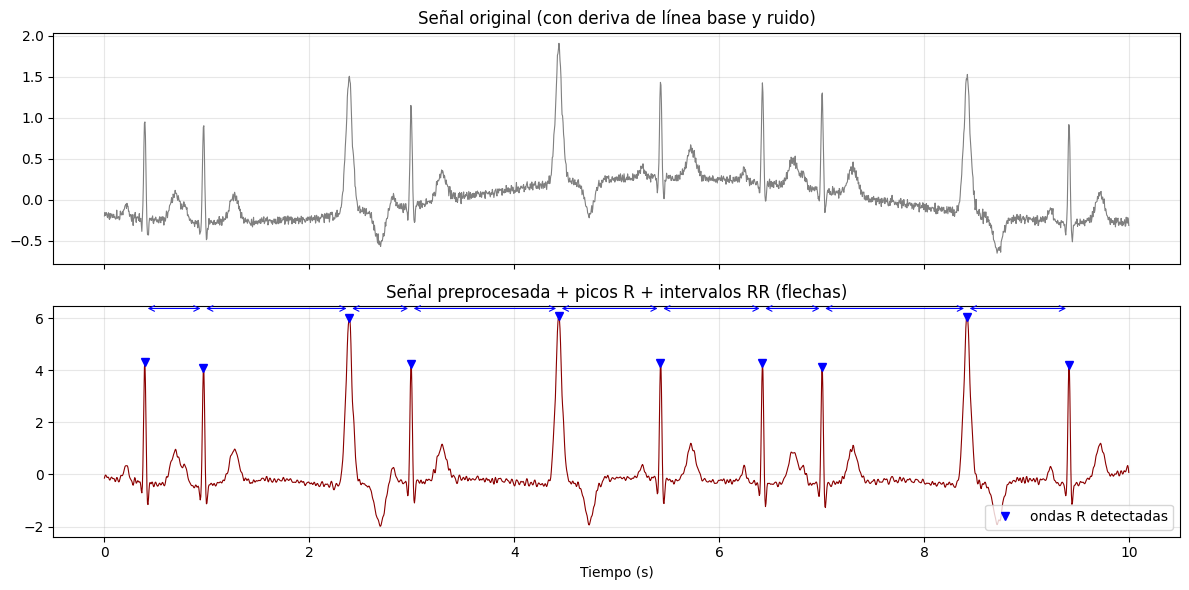

Intervalos RR (s): [0.57  1.425 0.6   1.445 0.99  0.995 0.585 1.41  0.995]


In [ ]:
ejemplo = ecgs[np.where(tipos == "esv")[0][0]]
limpia = preprocesar(ejemplo)
picos = detectar_picos_r(limpia)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(t_ecg, ejemplo, lw=0.8, color="gray")
axes[0].set_title("Señal original (con deriva de línea base y ruido)")
axes[1].plot(t_ecg, limpia, lw=0.8, color="darkred")
axes[1].plot(t_ecg[picos], limpia[picos], "bv", label="ondas R detectadas")
for p1, p2 in zip(picos[:-1], picos[1:]):
    axes[1].annotate("", xy=(t_ecg[p2], limpia.max() * 1.05), xytext=(t_ecg[p1], limpia.max() * 1.05),
                     arrowprops=dict(arrowstyle="<->", color="blue", lw=0.8))
axes[1].set_title("Señal preprocesada + picos R + intervalos RR (flechas)")
axes[1].set_xlabel("Tiempo (s)"); axes[1].legend(loc="lower right")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

rr = np.diff(picos) / FS
print("Intervalos RR (s):", rr.round(3))

🔎 **Observa los intervalos RR:** en un registro con extrasístoles aparece un RR **corto** (latido prematuro) seguido de uno **largo** (pausa compensatoria).

### Paso B: extraer características
De cada ECG calcularemos 6 números que resumen lo que un cardiólogo miraría:

| Característica | Qué mide | Por qué ayuda |
|---|---|---|
| `fc_media` | Frecuencia cardiaca promedio (lpm) | Taqui/bradicardia |
| `rr_cv` | Coeficiente de variación de los RR | **Regularidad** del ritmo |
| `rmssd` | Variación entre RR consecutivos (s) | Cambios bruscos latido a latido |
| `qrs_medio` | Ancho promedio del QRS (s) | **Morfología** del complejo |
| `qrs_max` | Ancho del QRS más ancho (s) | Detecta latidos ventriculares aislados |
| `onda_p` | Amplitud de la onda antes de cada R | Presencia de **onda P** |

In [ ]:
NOMBRES = ["fc_media", "rr_cv", "rmssd", "qrs_medio", "qrs_max", "onda_p"]

def extraer_caracteristicas(senal, fs=FS):
    x = preprocesar(senal, fs)
    r = detectar_picos_r(x, fs)
    rr = np.diff(r) / fs

    fc_media = 60 / rr.mean()
    rr_cv = rr.std() / rr.mean()
    rmssd = np.sqrt(np.mean(np.diff(rr) ** 2))

    anchos_qrs, ondas_p = [], []
    for p in r[1:-1]:
        # Ancho del QRS: tiempo que la onda R está por encima de la mitad de su altura
        mitad = x[p] / 2
        i, j = p, p
        while i > 0 and x[i] > mitad: i -= 1
        while j < len(x) - 1 and x[j] > mitad: j += 1
        anchos_qrs.append((j - i) / fs)
        # Onda P: buscamos una pequeña onda entre 250 y 100 ms antes de la R
        a, b = p - int(0.25 * fs), p - int(0.10 * fs)
        if a >= 0:
            ventana = x[a:b]
            ondas_p.append(ventana.max() - np.median(ventana))

    return [fc_media, rr_cv, rmssd, np.mean(anchos_qrs), np.max(anchos_qrs), np.mean(ondas_p)]

print("Características del ejemplo:")
for nombre, valor in zip(NOMBRES, extraer_caracteristicas(ejemplo)):
    print(f"  {nombre:10s} = {valor:.4f}")

Características del ejemplo:
  fc_media   = 59.9002
  rr_cv      = 0.3433
  rmssd      = 0.6475
  qrs_medio  = 0.0425
  qrs_max    = 0.0700
  onda_p     = 0.3198


Ahora lo aplicamos a los **10 000 registros** (toma unos 10–15 segundos):

In [ ]:
X = np.array([extraer_caracteristicas(s) for s in ecgs])
y = etiquetas

tabla = pd.DataFrame(X, columns=NOMBRES)
tabla["Etiqueta"] = registros["Etiqueta"]
print("Matriz de características X:", X.shape, "  -> (registros, características)")
tabla.head()

Matriz de características X: (10000, 6)   -> (registros, características)


,fc_media,rr_cv,rmssd,qrs_medio,qrs_max,onda_p,Etiqueta
0,119.122257,0.078814,0.060839,0.026111,0.03,0.617514,Normal
1,135.483871,0.088939,0.044399,0.029250,0.03,0.592589,Arritmia
2,122.824974,0.095749,0.077290,0.027368,0.03,0.485781,Normal
3,59.900166,0.066597,0.088530,0.026250,0.03,0.625200,Normal
4,121.729845,0.072130,0.048276,0.028333,0.03,0.631295,Normal


In [ ]:
# Promedio de cada característica según el tipo de registro
tabla.assign(Tipo=tipos).groupby("Tipo")[NOMBRES].mean().round(3)

,fc_media,rr_cv,rmssd,qrs_medio,qrs_max,onda_p
Tipo,,,,,,
esv,82.945,0.203,0.267,0.032,0.056,0.485
fa,104.696,0.145,0.129,0.028,0.031,0.575
normal,90.538,0.048,0.044,0.028,0.031,0.611


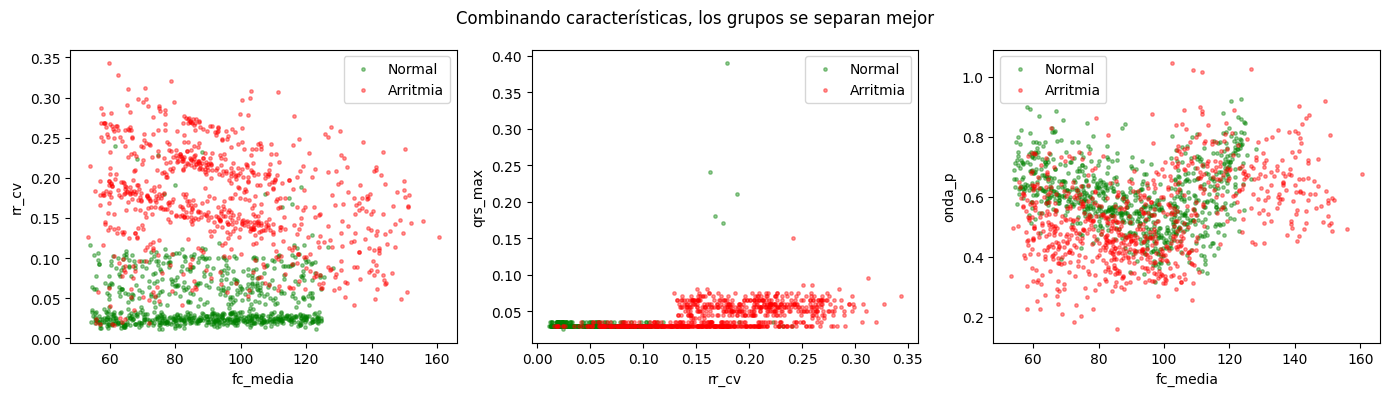

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pares = [("fc_media", "rr_cv"), ("rr_cv", "qrs_max"), ("fc_media", "onda_p")]
for ax, (a, b) in zip(axes, pares):
    ia, ib = NOMBRES.index(a), NOMBRES.index(b)
    for et, color, nombre in [(0, "green", "Normal"), (1, "red", "Arritmia")]:
        m = y == et
        ax.scatter(X[m, ia][:800], X[m, ib][:800], s=6, alpha=0.4, c=color, label=nombre)
    ax.set_xlabel(a); ax.set_ylabel(b); ax.legend()
plt.suptitle("Combinando características, los grupos se separan mejor"); plt.tight_layout(); plt.show()

✅ **Qué observar:** con **una** característica (FC) las clases se mezclan, pero combinando **varias** (regularidad RR, ancho del QRS, onda P) aparecen patrones. El problema: **¿cómo combinarlas?** ¿Qué peso darle a cada una? Justamente eso es lo que **aprenderá la red neuronal** (los pesos $w$).

### Paso C: dividir los datos en entrenamiento, validación y prueba
- **Entrenamiento (70 %)**: la red aprende con estos ejemplos.
- **Validación (15 %)**: vigilamos el aprendizaje y ajustamos decisiones.
- **Prueba (15 %)**: registros que la red **nunca ve** durante el entrenamiento → medimos el desempeño real.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=0, stratify=y_temp)

# Normalización Z-score de las características (se ajusta SOLO con entrenamiento)
escalador = StandardScaler().fit(X_train)
X_train_n, X_val_n, X_test_n = (escalador.transform(d) for d in (X_train, X_val, X_test))

print(f"Entrenamiento: {len(y_train)} | Validación: {len(y_val)} | Prueba: {len(y_test)}")

Entrenamiento: 7000 | Validación: 1500 | Prueba: 1500


---
## 5.4 Pregunta 3: ¿cómo sabría si su predicción es correcta o incorrecta?

Imagina que presentamos el registro **ECG_025** a la red y responde **90 % → Arritmia**. Si la etiqueta real es *Arritmia*, ¡acertó!

¿Y si la red dice *Normal* pero en realidad es *Arritmia*? Se produce un **error de predicción**. Para **medirlo** usamos una **función de pérdida**. En clasificación binaria se usa la **entropía cruzada binaria** (*Binary Cross-Entropy*):

$$L = -\left[\,y\,\log(p) + (1-y)\,\log(1-p)\,\right]$$

- $y$: etiqueta real (0 = Normal, 1 = Arritmia)
- $p$: probabilidad de arritmia predicha por el modelo
- $L$: valor de la pérdida

**Cuanto más equivocada y más segura sea la predicción, mayor es la penalización.**

In [ ]:
def bce(y_real, p):
    # Entropía cruzada binaria
    p = np.clip(p, 1e-9, 1 - 1e-9)          # evitamos log(0)
    return -(y_real * np.log(p) + (1 - y_real) * np.log(1 - p))

casos = [
    ("Arritmia real, red dice 90 % arritmia", 1, 0.90),
    ("Arritmia real, red dice 60 % arritmia", 1, 0.60),
    ("Arritmia real, red dice 30 % arritmia", 1, 0.30),
    ("Arritmia real, red dice  1 % arritmia", 1, 0.01),
    ("Normal real,   red dice  5 % arritmia", 0, 0.05),
    ("Normal real,   red dice 95 % arritmia", 0, 0.95),
]
for texto, yr, p in casos:
    print(f"{texto:40s} ->  L = {bce(yr, p):.3f}")

Arritmia real, red dice 90 % arritmia    ->  L = 0.105
Arritmia real, red dice 60 % arritmia    ->  L = 0.511
Arritmia real, red dice 30 % arritmia    ->  L = 1.204
Arritmia real, red dice  1 % arritmia    ->  L = 4.605
Normal real,   red dice  5 % arritmia    ->  L = 0.051
Normal real,   red dice 95 % arritmia    ->  L = 2.996


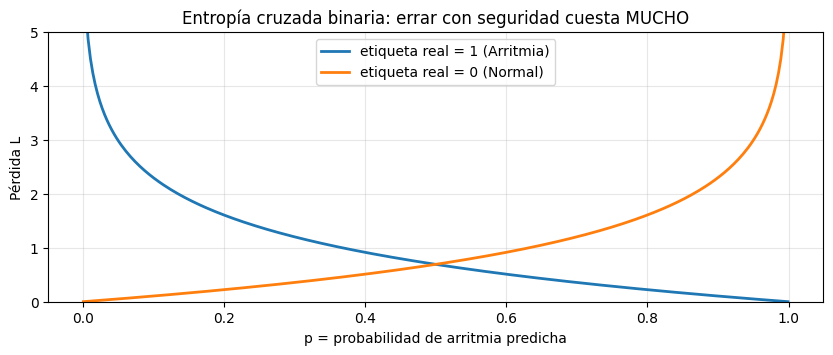

In [ ]:
p = np.linspace(0.001, 0.999, 300)
plt.plot(p, bce(1, p), label="etiqueta real = 1 (Arritmia)", lw=2)
plt.plot(p, bce(0, p), label="etiqueta real = 0 (Normal)", lw=2)
plt.xlabel("p = probabilidad de arritmia predicha"); plt.ylabel("Pérdida L")
plt.title("Entropía cruzada binaria: errar con seguridad cuesta MUCHO")
plt.ylim(0, 5); plt.legend(); plt.grid(alpha=0.3); plt.show()

✅ **Qué observar:** si el ECG es una arritmia ($y=1$) y la red dice $p \approx 1$, la pérdida es casi 0. Si dice $p \approx 0$ (muy segura y equivocada), la pérdida **se dispara**. La pérdida es la “nota” que le ponemos a la red: **queremos minimizarla**.

---
## 5.5 Pregunta 4: ¿cómo podría mejorar después de cometer un error?

Aquí aparece **el aprendizaje**. El proceso es:

1. La red recibe un ECG (sus características).
2. Realiza una predicción (**forward propagation**).
3. Comparamos la predicción con la etiqueta real.
4. Calculamos el error con la **función de pérdida** (BCE).
5. Usamos **Backpropagation** (regla de la cadena) para calcular cuánto contribuye cada peso al error: $\dfrac{\partial L}{\partial w}$.
6. Usamos **Gradient Descent** para actualizar: $w_{\text{nuevo}} = w_{\text{anterior}} - \alpha\,\dfrac{\partial L}{\partial w}$

Vamos a programar una red neuronal **desde cero, solo con NumPy**, para ver cada paso:

```
 6 características ──►  capa oculta (8 neuronas, ReLU) ──►  1 neurona de salida (sigmoide) ──► p(arritmia)
```

In [ ]:
class RedNeuronalECG:
    # Red de una capa oculta, entrenada con backpropagation + descenso de gradiente

    def __init__(self, n_entradas, n_ocultas, alpha=0.1, semilla=0):
        rng = np.random.default_rng(semilla)
        # Pesos iniciales aleatorios y pequeños; sesgos en cero
        self.W1 = rng.normal(0, np.sqrt(2 / n_entradas), (n_entradas, n_ocultas))
        self.b1 = np.zeros(n_ocultas)
        self.W2 = rng.normal(0, np.sqrt(1 / n_ocultas), (n_ocultas, 1))
        self.b2 = np.zeros(1)
        self.alpha = alpha                      # tasa de aprendizaje

    # ---------- 2) PREDICCIÓN: forward propagation ----------
    def forward(self, X):
        self.X = X
        self.z1 = X @ self.W1 + self.b1         # z = Σ w·x + b   (capa oculta)
        self.h = relu(self.z1)                  # y = f(z)        (activación ReLU)
        self.z2 = self.h @ self.W2 + self.b2    # z de la neurona de salida
        self.p = sigmoide(self.z2)              # probabilidad de arritmia
        return self.p

    # ---------- 4) EVALUACIÓN: función de pérdida ----------
    def perdida(self, y):
        return np.mean(bce(y.reshape(-1, 1), self.p))

    # ---------- 5) y 6) BACKPROPAGATION + GRADIENT DESCENT ----------
    def backward(self, y):
        m = len(y)
        y = y.reshape(-1, 1)
        dz2 = (self.p - y) / m                      # gradiente en la salida (BCE + sigmoide)
        dW2 = self.h.T @ dz2                        # ∂L/∂W2
        db2 = dz2.sum(axis=0)                       # ∂L/∂b2
        dh = dz2 @ self.W2.T                        # regla de la cadena: el error "viaja hacia atrás"
        dz1 = dh * (self.z1 > 0)                    # derivada de ReLU
        dW1 = self.X.T @ dz1                        # ∂L/∂W1
        db1 = dz1.sum(axis=0)                       # ∂L/∂b1
        # w_nuevo = w_anterior - alpha * ∂L/∂w
        self.W2 -= self.alpha * dW2;  self.b2 -= self.alpha * db2
        self.W1 -= self.alpha * dW1;  self.b1 -= self.alpha * db1

    def predecir(self, X):
        return (self.forward(X) >= 0.5).astype(int).ravel()

### ¿Qué tal lo hace la red **antes** de aprender?
Con pesos aleatorios, la red “adivina”:

In [ ]:
red = RedNeuronalECG(n_entradas=6, n_ocultas=8, alpha=0.5, semilla=1)

red.forward(X_train_n)
print(f"Pérdida inicial: {red.perdida(y_train):.3f}")
print(f"Exactitud inicial (sin entrenar): {np.mean(red.predecir(X_val_n) == y_val)*100:.1f} %")

Pérdida inicial: 0.712
Exactitud inicial (sin entrenar): 48.3 %


### Entrenamiento: repetimos el ciclo muchas veces
Cada repetición sobre todo el conjunto de entrenamiento se llama **época**.

In [ ]:
epocas = 1500
hist_perdida_train, hist_perdida_val, hist_exactitud_val = [], [], []

for epoca in range(epocas):
    red.forward(X_train_n)                      # 1-2) entrada y predicción
    hist_perdida_train.append(red.perdida(y_train))   # 3-4) evaluación
    red.backward(y_train)                       # 5-6) backprop + actualización

    # Vigilamos el desempeño en validación (sin actualizar pesos)
    red.forward(X_val_n)
    hist_perdida_val.append(red.perdida(y_val))
    hist_exactitud_val.append(np.mean(red.predecir(X_val_n) == y_val))

    if epoca % 300 == 0 or epoca == epocas - 1:
        print(f"Época {epoca:4d} | pérdida entrenamiento: {hist_perdida_train[-1]:.4f} "
              f"| exactitud validación: {hist_exactitud_val[-1]*100:.1f} %")

Época    0 | pérdida entrenamiento: 0.7118 | exactitud validación: 60.9 %
Época  300 | pérdida entrenamiento: 0.1747 | exactitud validación: 92.2 %
Época  600 | pérdida entrenamiento: 0.1636 | exactitud validación: 92.7 %
Época  900 | pérdida entrenamiento: 0.1573 | exactitud validación: 92.9 %
Época 1200 | pérdida entrenamiento: 0.1525 | exactitud validación: 93.1 %
Época 1499 | pérdida entrenamiento: 0.1491 | exactitud validación: 93.2 %


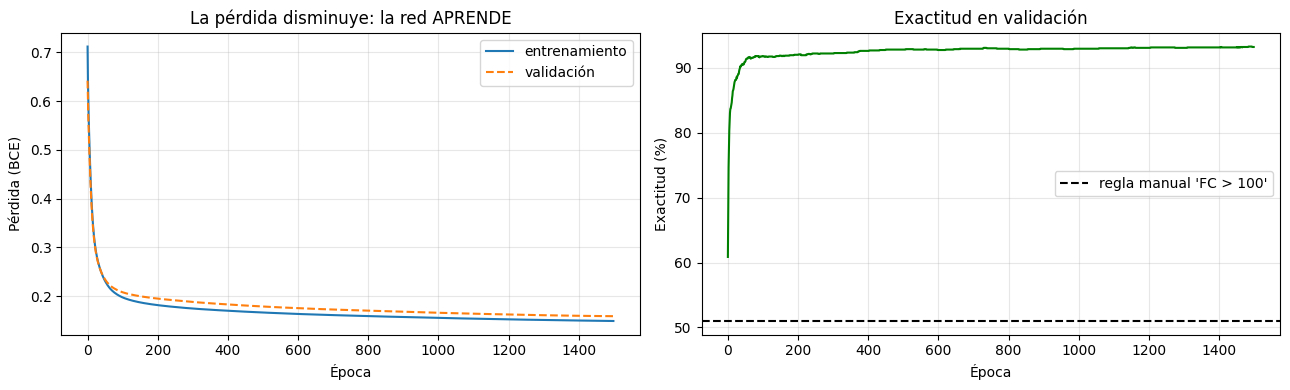

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist_perdida_train, label="entrenamiento")
ax[0].plot(hist_perdida_val, "--", label="validación")
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida (BCE)"); ax[0].set_title("La pérdida disminuye: la red APRENDE")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(np.array(hist_exactitud_val) * 100, color="green")
ax[1].axhline(exactitud_regla * 100, color="k", ls="--", label="regla manual 'FC > 100'")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Exactitud (%)"); ax[1].set_title("Exactitud en validación")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

✅ **Qué observar:**
- La pérdida **baja** época tras época: cada actualización de pesos corrige un poco los errores.
- Las curvas de entrenamiento y validación van juntas: la red **generaliza** a registros que no usó para aprender (no está “memorizando”).
- La exactitud supera con amplitud a la regla manual.

### ¿Qué aprendió la red? Mirando los pesos
Los pesos de la primera capa indican cuánto “escucha” cada neurona oculta a cada característica:

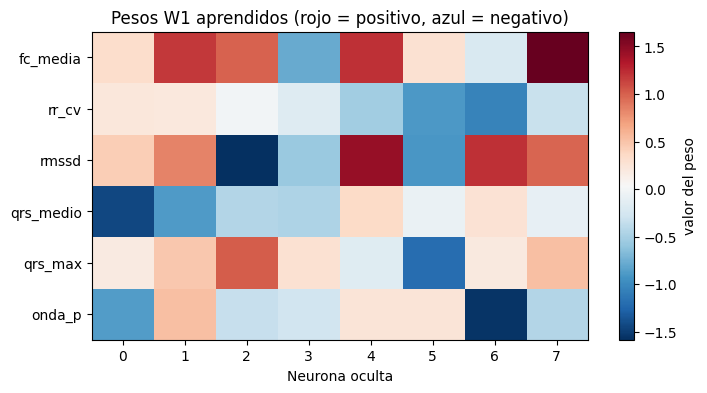

In [ ]:
plt.figure(figsize=(8, 4))
plt.imshow(red.W1, cmap="RdBu_r", aspect="auto")
plt.colorbar(label="valor del peso")
plt.yticks(range(6), NOMBRES); plt.xlabel("Neurona oculta")
plt.title("Pesos W1 aprendidos (rojo = positivo, azul = negativo)"); plt.show()

---
## 5.6 Integramos las cuatro respuestas: el sistema completo

| Etapa | ¿Qué hacemos? | En este cuaderno |
|---|---|---|
| 1. Recolección | Obtenemos 10 000 registros ECG | `generar_ecg` (en la práctica: MIT-BIH) |
| 2. Etiquetado | Identificamos los registros según su diagnóstico | `etiquetas` |
| 3. Preprocesamiento | Limpiamos señales, quitamos ruido y normalizamos | `preprocesar` |
| 4. División | Entrenamiento, validación y prueba | `train_test_split` |
| 5. Entrenamiento | La red aprende patrones | `MLPClassifier` |
| 6. Evaluación | Medimos el desempeño con registros no usados | matriz de confusión |
| 7. Predicción | Analizamos nuevos registros ECG | `analizar_ecg` |

En la práctica no programamos la red desde cero: usamos librerías como **scikit-learn** (o TensorFlow/PyTorch para redes profundas), que hacen lo mismo de forma optimizada.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# 5. Entrenamiento: red con 2 capas ocultas (16 y 8 neuronas)
modelo = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu",
                       learning_rate_init=0.001, max_iter=500,
                       early_stopping=True, random_state=0)
modelo.fit(X_train_n, y_train)

# 6. Evaluación con registros que la red NUNCA vio
y_pred = modelo.predict(X_test_n)
print(f"Exactitud en PRUEBA (red neuronal): {accuracy_score(y_test, y_pred)*100:.1f} %")
print(f"Exactitud de la regla manual:       {exactitud_regla*100:.1f} %\n")
print(classification_report(y_test, y_pred, target_names=["Normal", "Arritmia"]))

Exactitud en PRUEBA (red neuronal): 92.7 %
Exactitud de la regla manual:       51.0 %

              precision    recall  f1-score   support

      Normal       0.91      0.95      0.93       740
    Arritmia       0.95      0.91      0.93       760

    accuracy                           0.93      1500
   macro avg       0.93      0.93      0.93      1500
weighted avg       0.93      0.93      0.93      1500



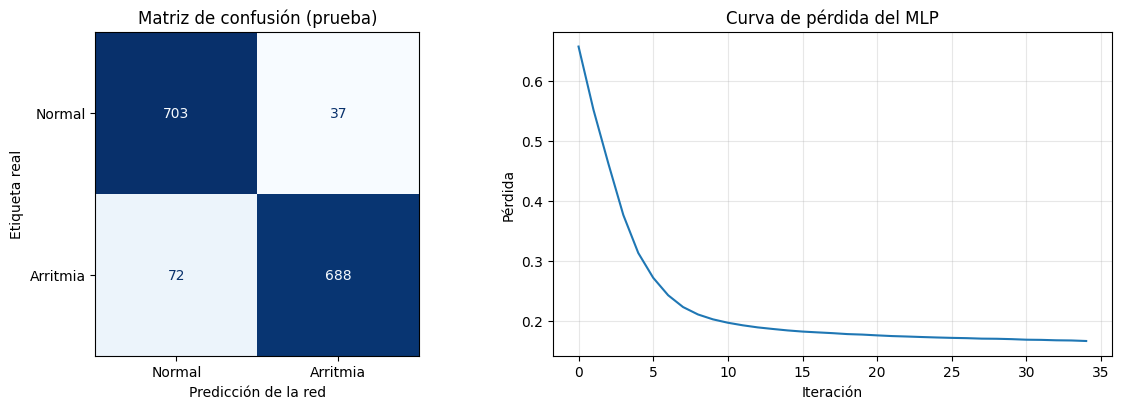

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Normal", "Arritmia"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Matriz de confusión (prueba)")
ax[0].set_xlabel("Predicción de la red"); ax[0].set_ylabel("Etiqueta real")
ax[1].plot(modelo.loss_curve_); ax[1].set_title("Curva de pérdida del MLP")
ax[1].set_xlabel("Iteración"); ax[1].set_ylabel("Pérdida"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Cómo leer la matriz de confusión:**
- La **diagonal** son los aciertos.
- **Falso negativo** (real *Arritmia*, predicho *Normal*): el más peligroso en clínica, porque un paciente enfermo no recibe atención.
- **Falso positivo** (real *Normal*, predicho *Arritmia*): genera alarmas innecesarias y estudios adicionales.

### 7. Predicción: analizamos un ECG completamente nuevo

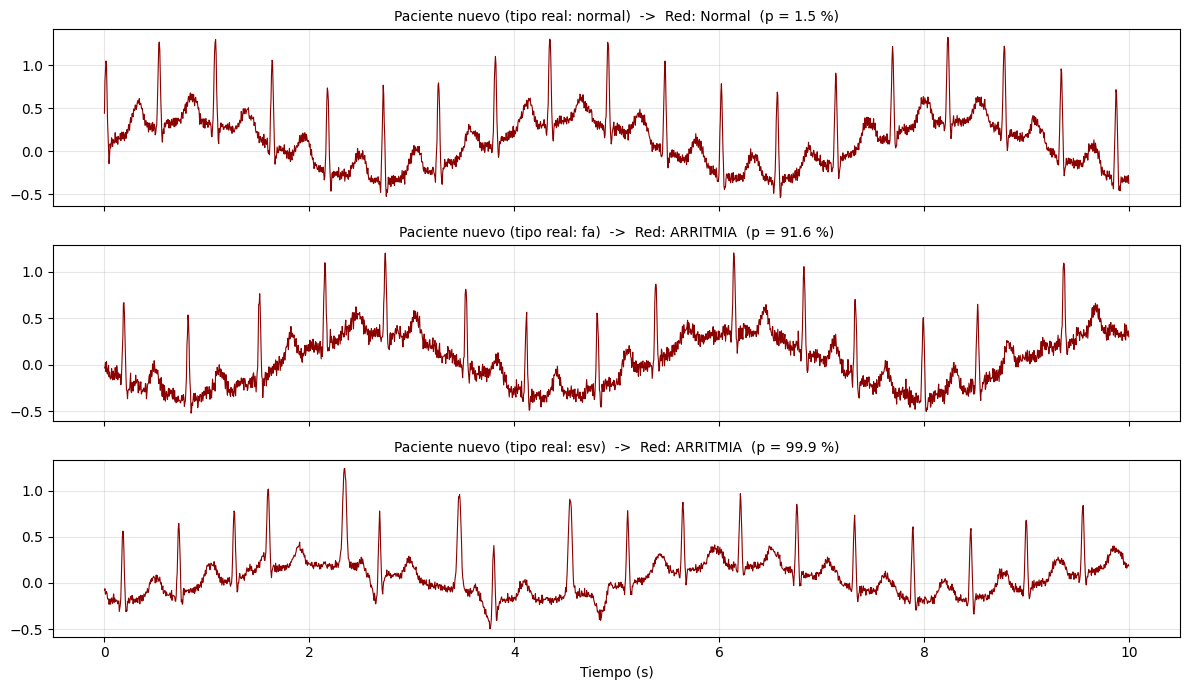

In [ ]:
def analizar_ecg(senal):
    # Sistema completo: señal cruda -> preprocesamiento -> características -> red neuronal -> diagnóstico
    caracteristicas = np.array(extraer_caracteristicas(senal)).reshape(1, -1)
    p = modelo.predict_proba(escalador.transform(caracteristicas))[0, 1]
    return p

rng_nuevo = np.random.default_rng(999)
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, tipo in zip(axes, ["normal", "fa", "esv"]):
    nuevo = generar_ecg(tipo, rng_nuevo)            # un paciente que la red jamás vio
    p = analizar_ecg(nuevo)
    resultado = "ARRITMIA" if p >= 0.5 else "Normal"
    ax.plot(t_ecg, nuevo, lw=0.8, color="darkred")
    ax.set_title(f"Paciente nuevo (tipo real: {tipo})  ->  Red: {resultado}  (p = {p*100:.1f} %)", fontsize=10)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

### 💡 ¿Y el Deep Learning?
Nosotros **diseñamos** las 6 características. En *Deep Learning* (por ejemplo, una **red convolucional 1D**, como en el diagrama de la clase) se entrega la señal ECG preprocesada directamente y la red **aprende sola qué características mirar**. Requiere más datos y más cómputo (GPU), pero puede descubrir patrones que no se nos ocurrieron. Ese será el siguiente paso del curso.

⚠️ **Nota importante:** usamos datos **simulados**, más “limpios” que los reales, así que la exactitud es optimista. Con datos clínicos reales el problema es más difícil, y cualquier sistema así es una herramienta de **apoyo** al especialista, no un reemplazo.

---
## 6. Conclusiones

1. **No** le explicamos a la computadora todas las reglas de una arritmia (la regla manual apenas llegó a ~50 %).
2. Le **proporcionamos ejemplos** de señales ECG con sus etiquetas.
3. La computadora usó esos ejemplos para encontrar patrones. Al principio se equivocaba, y **medimos ese error** con una función matemática: la pérdida BCE.
4. Con **Backpropagation** y **Gradient Descent** ajustamos los parámetros internos (pesos y sesgos) de la red.
5. Repetimos el proceso muchas veces (épocas) hasta obtener un modelo que **reconoce patrones en señales que nunca había visto**.

> **Entrenar una red neuronal es aprender relaciones matemáticas a partir de ejemplos para hacer predicciones sobre datos nuevos.**

---
## 7. Ejercicios propuestos 📝

Completa las partes marcadas con `# TODO`.

### Ejercicio 1 — Mejorar las reglas manuales
Combina varias condiciones (por ejemplo, `rr_cv` alto **o** `qrs_max` ancho) para crear una regla manual mejor que “FC > 100”. ¿Hasta qué exactitud llegas? ¿Cuánto tiempo te tomó encontrar los umbrales?

In [ ]:
fc_m, rr_cv, rmssd, qrs_medio, qrs_max, onda_p = X_test.T     # columnas del conjunto de prueba

regla = (rr_cv > 0.09) | (qrs_max > 0.04)

print(f"Exactitud de tu regla: {np.mean(regla.astype(int) == y_test)*100:.1f} %")

Exactitud de tu regla: 87.7 %


Respuesta: La regla de FC > 100 acierta apenas un 51 %. En la tabla de promedios se ve que en los normales el rr_cv es bajo (0.05) y en FA y ESV es alto (0.15 y 0.20). En las ESV el qrs_max también es más ancho (0.056 s contra 0.031 s). Con la regla rr_cv > 0.09 o qrs_max > 0.04 llegué a 87.7 %. Me tomó unos 15 minutos probando umbrales, y aun así la red neuronal sale mejor (92.7 %).

### Ejercicio 2 — Calcula la pérdida a mano
Una red predice $p = 0.2$ para un ECG con arritmia ($y = 1$). Calcula $L$ con la fórmula usando `np.log` y comprueba tu resultado con la función `bce`. Luego responde: ¿qué valor de $p$ haría que $L = 0.1$?

In [ ]:
L_manual = -(1 * np.log(0.2) + (1 - 1) * np.log(1 - 0.2))
print("L manual:", L_manual, "| L con bce():", bce(1, 0.2))

p_L = np.exp(-0.1)
print("p para L = 0.1:", p_L)

L manual: 1.6094379124341003 | L con bce(): 1.6094379124341003
p para L = 0.1: 0.9048374180359595


Respuesta: Con y = 1 y p = 0.2 queda L = -log(0.2) = 1.609, igual que con bce(). Para que L = 0.1 se necesita p = e^(-0.1) = 0.905.

### Ejercicio 3 — Efecto de la tasa de aprendizaje $\alpha$
Entrena `RedNeuronalECG` con `alpha = 0.01`, `0.5` y `3.0` durante 500 épocas y grafica las tres curvas de pérdida juntas. ¿Qué ocurre si $\alpha$ es muy pequeño? ¿Y si es muy grande?

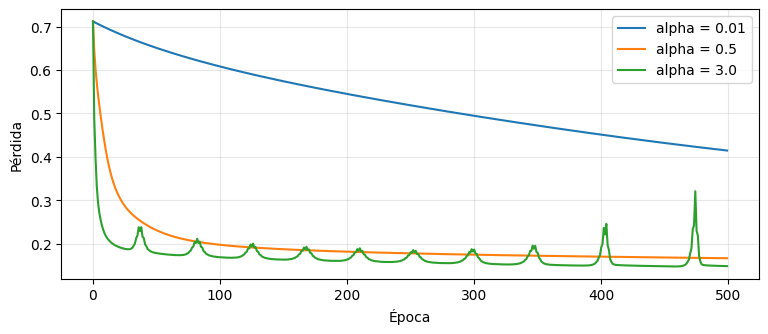

In [ ]:
plt.figure(figsize=(9, 3.5))
for alpha in [0.01, 0.5, 3.0]:
    r = RedNeuronalECG(6, 8, alpha=alpha, semilla=1)
    perdidas = []
    for _ in range(500):
        r.forward(X_train_n); perdidas.append(r.perdida(y_train)); r.backward(y_train)
    plt.plot(perdidas, label=f"alpha = {alpha}")
plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Respuesta: Con alpha = 0.01 la pérdida baja muy lento y a las 500 épocas todavía sigue alta. Con alpha = 0.5 baja rápido y de forma estable. Con alpha = 3.0 baja rápido al inicio pero tiene picos, porque los pasos son tan grandes que se pasa del mínimo. Si alpha es muy pequeño aprende lento y si es muy grande se vuelve inestable.

### Ejercicio 4 — ¿Qué característica es más importante?
Entrena el `MLPClassifier` **quitando una característica a la vez** y anota la exactitud en prueba. ¿Sin cuál cae más el desempeño? ¿Tiene sentido fisiológico? ¿Por qué quitar algunas casi no afecta? (pista: *redundancia*)

In [ ]:
for i, nombre in enumerate(NOMBRES):
    columnas = [j for j in range(6) if j != i]       # todas menos la i
    m = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500, early_stopping=True, random_state=0)
    m.fit(X_train_n[:, columnas], y_train)
    exactitud = m.score(X_test_n[:, columnas], y_test)
    print(f"Sin {nombre:10s} -> exactitud = {exactitud*100:.1f} %")

Sin fc_media   -> exactitud = 91.7 %
Sin rr_cv      -> exactitud = 93.2 %
Sin rmssd      -> exactitud = 92.7 %
Sin qrs_medio  -> exactitud = 93.1 %
Sin qrs_max    -> exactitud = 92.3 %
Sin onda_p     -> exactitud = 90.3 %


Respuesta: Con las 6 características la exactitud es 92.7 %. Sin onda_p baja a 90.3 %, que es la caída más grande. Tiene sentido porque ni la FA ni las ESV tienen onda P antes del QRS. Quitar las otras casi no cambia nada porque son redundantes: rr_cv y rmssd miden la irregularidad del RR, y qrs_medio y qrs_max miden el ancho del QRS.

### Ejercicio 5 — Clasificación multiclase
En vez de *Normal / Arritmia*, entrena una red que distinga los **tres tipos**: `normal`, `fa` y `esv` (usa el arreglo `tipos` como etiqueta). Muestra la matriz de confusión 3×3. ¿Qué tipos se confunden más?

Exactitud con 3 clases: 91.8 %


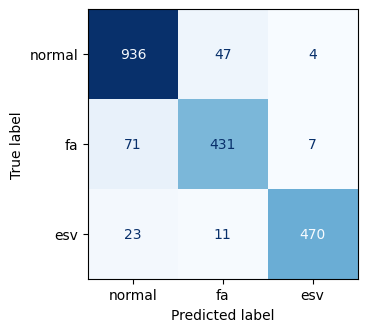

In [ ]:
clases = ["normal", "fa", "esv"]
y3 = np.array([clases.index(t) for t in tipos])

Xtr3, Xte3, t_tr, t_te = train_test_split(X, y3, test_size=0.2, random_state=0, stratify=y3)

esc3 = StandardScaler().fit(Xtr3)
red3 = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=500, early_stopping=True, random_state=0)
red3.fit(esc3.transform(Xtr3), t_tr)

pred_t = red3.predict(esc3.transform(Xte3))
print(f"Exactitud con 3 clases: {accuracy_score(t_te, pred_t)*100:.1f} %")

ConfusionMatrixDisplay(confusion_matrix(t_te, pred_t), display_labels=clases).plot(cmap="Blues", colorbar=False)
plt.show()

Respuesta: La exactitud con 3 clases fue 91.8 %. Las ESV casi siempre se reconocen bien por su QRS ancho. Lo que más se confunde es FA con normal: 71 FA salieron como normales y 47 normales como FA. Las dos tienen QRS estrecho y algunos normales tienen el RR un poco variable por la respiración.

### Ejercicio 6 — Preguntas de reflexión (responde en una celda de texto)
1. ¿Por qué la regla “FC > 100 lpm” falla tanto? Da dos ejemplos fisiológicos.
2. ¿Por qué dividimos los datos en entrenamiento, validación y prueba?
3. En la matriz de confusión, ¿qué error es más grave en un sistema de monitoreo cardiaco y por qué?
4. ¿Qué diferencia hay entre el enfoque que usamos (características diseñadas por nosotros) y el Deep Learning?

Respuestas:

1. Porque la FC sola no dice si el ritmo es normal. Una persona sana haciendo ejercicio puede pasar de 100 lpm y estar normal, y alguien con extrasístoles puede tener 75 lpm y sí tener arritmia.

2. Con entrenamiento la red aprende, con validación revisamos cómo va mientras entrena y con prueba medimos qué tan bien funciona con datos que nunca vio. Si probáramos con los mismos datos de entrenamiento el resultado saldría inflado.

3. El falso negativo, porque el paciente tiene una arritmia y el sistema dice que está normal, entonces no recibe atención a tiempo. El falso positivo solo da una alarma de más.

4. Nosotros elegimos qué medir de la señal (FC, RR, QRS, onda P) y la red solo combina esos datos. En Deep Learning se le da la señal completa y la red aprende sola qué mirar, pero necesita más datos y más cómputo.

---
## 🔑 Soluciones (revísalas después de intentarlo)

In [ ]:
# Ejercicio 1: buscamos los mejores umbrales probando MUCHAS combinaciones (en entrenamiento)
fc_tr, cv_tr, _, _, qx_tr, _ = X_train.T
mejor = (0, None, None)
for u_cv in np.linspace(0.02, 0.20, 19):
    for u_qrs in np.linspace(0.02, 0.10, 17):
        acc = np.mean(((cv_tr > u_cv) | (qx_tr > u_qrs)).astype(int) == y_train)
        if acc > mejor[0]:
            mejor = (acc, u_cv, u_qrs)
_, u_cv, u_qrs = mejor
regla = (rr_cv > u_cv) | (qrs_max > u_qrs)
print(f"Ej.1 - Probamos {19*17} combinaciones de umbrales. Mejor regla: rr_cv > {u_cv:.2f} o qrs_max > {u_qrs:.3f}")
print(f"       Exactitud en prueba de la regla combinada: {np.mean(regla.astype(int) == y_test)*100:.1f} %"
      f"  vs. red neuronal: {accuracy_score(y_test, y_pred)*100:.1f} %")

# Ejercicio 2
L_manual = -(1 * np.log(0.2) + 0 * np.log(0.8))
print(f"Ej.2 - L manual = {L_manual:.4f} | bce = {bce(1, 0.2):.4f} | p para L=0.1: {np.exp(-0.1):.3f}")

# Ejercicio 4
print("\nEj.4 - Importancia por eliminación:")
for i, nombre in enumerate(NOMBRES):
    columnas = [j for j in range(6) if j != i]
    m = MLPClassifier((16, 8), max_iter=500, early_stopping=True, random_state=0).fit(X_train_n[:, columnas], y_train)
    print(f"  Sin {nombre:10s} -> exactitud = {m.score(X_test_n[:, columnas], y_test)*100:.1f} %")

# Ejercicio 5
Xtr, Xte, ttr, tte = train_test_split(X, tipos, test_size=0.2, random_state=0, stratify=tipos)
esc = StandardScaler().fit(Xtr)
m3 = MLPClassifier((16, 8), max_iter=500, early_stopping=True, random_state=0).fit(esc.transform(Xtr), ttr)
pred3 = m3.predict(esc.transform(Xte))
print(f"\nEj.5 - Exactitud multiclase: {accuracy_score(tte, pred3)*100:.1f} %")
ConfusionMatrixDisplay(confusion_matrix(tte, pred3, labels=["normal", "fa", "esv"]),
                       display_labels=["normal", "fa", "esv"]).plot(cmap="Blues", colorbar=False)
plt.title("Ej.5 - Matriz de confusión multiclase"); plt.show()

Ej.1 - Probamos 323 combinaciones de umbrales. Mejor regla: rr_cv > 0.11 o qrs_max > 0.035
       Exactitud en prueba de la regla combinada: 89.6 %  vs. red neuronal: 92.7 %
Ej.2 - L manual = 1.6094 | bce = 1.6094 | p para L=0.1: 0.905

Ej.4 - Importancia por eliminación:
  Sin fc_media   -> exactitud = 91.7 %
  Sin rr_cv      -> exactitud = 93.2 %
  Sin rmssd      -> exactitud = 92.7 %
  Sin qrs_medio  -> exactitud = 93.1 %
  Sin qrs_max    -> exactitud = 92.3 %
  Sin onda_p     -> exactitud = 90.3 %


TypeError: ufunc 'isnan' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

---
📖 **Para profundizar:** Hardt & Recht, *Patterns, predictions, and actions* — https://mlstory.org/
🫀 **Datos reales de ECG:** MIT-BIH Arrhythmia Database en PhysioNet — https://physionet.org/content/mitdb/